In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
divar_df = pd.read_csv('./Divar.csv')

In [32]:
# handling outliers of price_value, land_size and building size
columns = ['price_value', 'land_size', 'building_size']
for _ in columns: 
    Q1 = divar_df[_].quantile(0.25)
    Q3 = divar_df[_].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    divar_df = divar_df[((divar_df[_] >= lower_bound) & (divar_df[_] <= upper_bound)) | divar_df[_].isna()]

In [33]:
mapping = {
    'بدون اتاق': 0,
    'یک': 1,
    'دو': 2,
    'سه': 3,
    'چهار': 4,
    'پنج یا بیشتر': 5,
}
divar_df['rooms_count'] = divar_df['rooms_count'].map(mapping).astype(float)

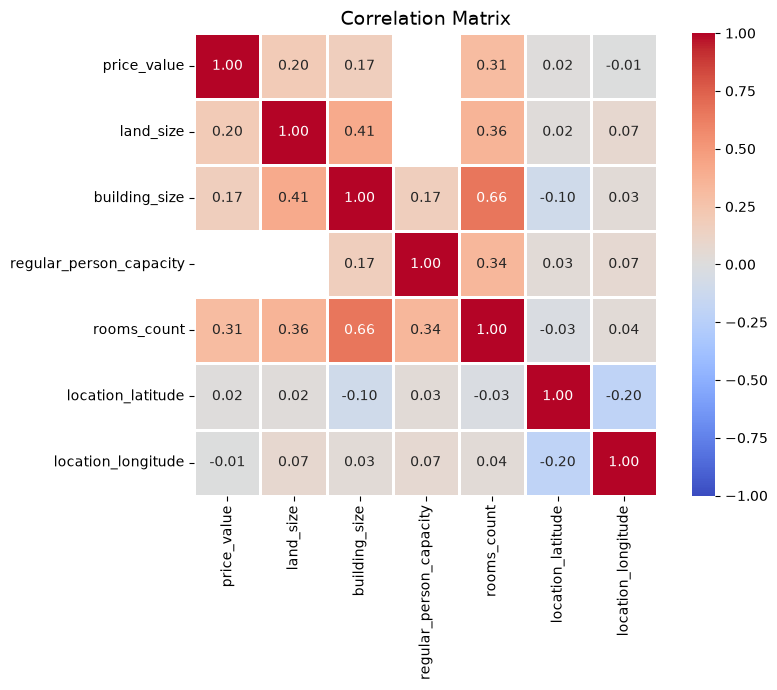

In [34]:
columns = ['price_value',
        'land_size',
        'building_size',
        'regular_person_capacity',
        'rooms_count',
        'location_latitude',
        'location_longitude']

matrix = divar_df[columns].copy()
corr = matrix.corr(method='pearson')
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    linewidths=0.75,
    vmin=-1,
    vmax=1,
)

plt.title("Correlation Matrix", fontsize=14)
plt.tight_layout()
plt.show()